<div style="text-align: center;">
   <font size="5"> 2025年度　数値計算実習　ペア試験問題 </font>
</div>
   <div style="text-align: right;">
   <font size="3"> cc by Shigeto R. Nishitani, 2025/11/20実施 </font>
</div>

- file: ~/symbolic_math/exam_25_pair/25_pair_ans.ipynb
- make problem: pick_works_from_ans 25_pair_ans.ipynb -1 '' '30 31'

以下の問題を python で解き，LUNA へ提出せよ．LUNA へは ipynb と pdf 形式の２種類を提出すること．

# 問１微積分

2変数のソフトマックス関数は
$$
y_1 = \frac{e^{x_1}}{\sum_{j=1}^2 e^{x_j}}\,  (i=1,2)
$$
で与えられる．


In [1]:
import numpy as np

def softmax(x):
  if (x.ndim == 1):
    x = x[None,:]    # ベクトル形状なら行列形状に変換
  # テンソル（x：行列）、軸（axis=1： 列の横方向に計算）
  return np.exp(x) / np.sum(np.exp(x), axis=1, keepdims=True)

# 入力（x）と出力（y）の例
x = np.array([[4,0,0], [0,xp,0], [0,0,yp]]) 
y = softmax(x)
print(y)  # 以下のように出力される

[[0.57611688 0.21194156 0.21194156]
 [0.21194156 0.57611688 0.21194156]
 [0.21194156 0.21194156 0.57611688]]


In [24]:
import struct
import binascii

def hex_to_float(s):
    if s.startswith('0x'):
        s = s[2:]
    s = s.replace(' ', '')
    return struct.unpack('>f', binascii.unhexlify(s))[0]

print(hex_to_float('0x5f400000'))
print(hex_to_float('0x5f3759df'))
# 42.19499969482422

1.3835058055282164e+19
1.3211836172961055e+19


In [26]:
hex_to_float('0x5f3759df')/(2**23)

1574973603840.0

In [1]:
import numpy as np


def invsqrt(x):
    # y = 1/sqrt(x) = 2 ^ (-1/2 * log2(x))
    x = np.array(x, dtype=np.float32)
    X = x.view(np.int32)
    Y = np.int32(0x5F3759DF) - (X >> 1)
    y = Y.view(np.float32)

    # Newton's method
    threehalfs = 1.5
    x2 = x * 0.5
    y = y * (threehalfs - (x2 * y * y))  # 1st iteration
    #y = y * (threehalfs - (x2 * y * y))  # 2nd iteration (optional)

    return y

xs = np.arange(1, 11, dtype=np.float32)
ys = 1 / np.sqrt(xs)
fys = invsqrt(xs)

for x, y, fy in zip(xs, ys, fys):
    print(f"{x}, {y}, {fy}")

1.0, 1.0, 0.9983071684837341
2.0, 0.7071067690849304, 0.7069300413131714
3.0, 0.5773502588272095, 0.5768468379974365
4.0, 0.5, 0.49915358424186707
5.0, 0.4472135901451111, 0.44714102149009705
6.0, 0.40824827551841736, 0.4076813757419586
7.0, 0.37796449661254883, 0.37744417786598206
8.0, 0.3535533845424652, 0.3534650206565857
9.0, 0.3333333432674408, 0.33295321464538574
10.0, 0.3162277638912201, 0.31568577885627747


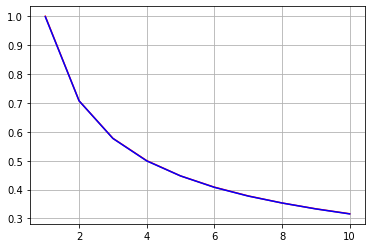

In [29]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.plot(xs, ys, color='r')
plt.plot(xs,fys, color='b')

plt.grid()
plt.show()

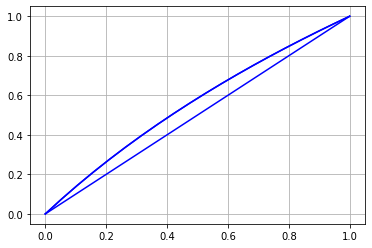

In [30]:
x =np.linspace(0,1,20)
plt.plot(x,x, color='b')
plt.plot(x,np.log2(x+1), color='b')
plt.plot(x,np.log2(x+1), color='b')

plt.grid()
plt.show()

# 問２　線形代数

## (15 点)

$\mathbb{R}^4$のベクトル
$$
a=\left(
    \begin{array}{@{\,}c@{\,}}
      3 \\
      -5 \\
      -2 \\
      1
    \end{array}
    \right)
    $$
をベクトル
$$
a_1=\left(
    \begin{array}{@{\,}c@{\,}}
      1 \\
      0 \\
      1 \\
      1
    \end{array}
    \right),~
a_2=\left(
    \begin{array}{@{\,}c@{\,}}
    0\\
    1\\
    1\\
    1
    \end{array}
    \right),~
a_3=\left(
    \begin{array}{@{\,}c@{\,}}
    0\\
    1\\
    1\\
    0
    \end{array}
    \right)
$$
の一次結合で表せ．Moore-Penrose pseudo-inverse(np.linalg.pinv)を使え．

In [31]:
import numpy as np

a_1 = np.array([1,0,1,1])
a_2 = np.array([0,1,1,1])
a_3 = np.array([0,1,1,0])
AA = np.transpose(np.vstack((a_1,a_2,a_3)))
AA

array([[1, 0, 0],
       [0, 1, 1],
       [1, 1, 1],
       [1, 1, 0]])

In [32]:
a = 3*a_1-2*a_2-3*a_3
a

array([ 3, -5, -2,  1])

In [33]:
np.linalg.pinv(AA).dot(a)

array([ 3., -2., -3.])

## QRDecomposition(15 点)

$$
A=\left(
    \begin{array}{@{\,}c@{\,}c@{\,}c@{\,}}
      1 & -2 & 4\\
      1 & -1 & 1\\
      1 & 1 & 1\\
      1 & 2  & 4
    \end{array}
    \right)
$$

に対してQRDecompositionによって直交行列QとR行列を求めよ．

さらに，列ベクトル$yy$ 
$$
yy=\left(
    \begin{array}{@{\,}c@{\,}}
      3\\
      1 \\
      1 \\
      4
    \end{array}
    \right)
$$
に対して$R^{-1}Q^{T}yy$ を計算せよ．



得られた解は，４つのデータ[[-2,3],[-1,1],[1,1],[2,4]]に対する2次関数$f(x)=a_0+a_1\,x+a_2\,x^2$ による最小2乗近似となる．


In [34]:
import numpy as np

a_1 = np.array([1,1,1,1])
a_2 = np.array([-2,-1,1,2])
a_3 = np.array([4,1,1,4])

In [35]:
AA = np.transpose(np.vstack((a_1,a_2,a_3)))

In [36]:
np.linalg.qr(AA)

(array([[-0.5       , -0.63245553,  0.5       ],
        [-0.5       , -0.31622777, -0.5       ],
        [-0.5       ,  0.31622777, -0.5       ],
        [-0.5       ,  0.63245553,  0.5       ]]),
 array([[-2.        ,  0.        , -5.        ],
        [ 0.        ,  3.16227766,  0.        ],
        [ 0.        ,  0.        ,  3.        ]]))

In [37]:
yy=np.array([3,1,1,4])

In [38]:
Q, R = np.linalg.qr(AA)
pp = np.dot(np.dot(np.linalg.inv(R),np.transpose(Q)),yy)
pp

array([0.16666667, 0.2       , 0.83333333])

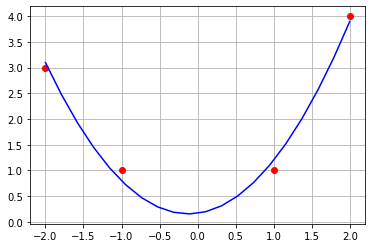

In [39]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

def f(x, a0, a1,a2):
    return a0 + a1*x +a2* x*x

xdata = a_2
ydata = yy
plt.plot(xdata,ydata, 'o', color='r')

x =np.linspace(-2,2,20)
y = f(x, pp[0], pp[1], pp[2])  #,params[2])
plt.plot(x,y, color='b')

plt.grid()
plt.show()

# 問3 共通テスト(20 点)

2024年度：数学II・B/本試験第２問[1]


$m$を$m > 1$を満たす定数とし、$f(x) = 3 (x - 1)(x - m)$とする。また、
$S(x) =\int_0^x f(t) dt$とする。
関数$y = f(x)$ と$y = S(x)$ のグラフの関係
について考えてみよう。

(1) $m = 2$のとき、すなわち, $f(x)=3 (x-1) (x-2)$のときを考える。

(i) $f'(x) = 0$ となる$x$の値は
$x=\frac{\fbox{ ア }}{\fbox{ イ }}$　である。


(ⅱ) $S(x)$ を計算すると
$$
S(x)=\int_0^x f(t)dt
$$
$$
= \int_0^x\left(3t^2-\fbox{ ウ }t+\fbox{ エ }\right) dt
$$
$$
= x^3- \frac{\fbox{ オ }}{\fbox{ カ }}x^2 +\fbox{ キ } x
$$
であるから

$x=\fbox{ ク }$のとき, $S(x)$は極大値 $\frac{\fbox{ ケ }}{\fbox{ コ }}$をとり


$x=\fbox{ サ }$のとき, $S(x)$は極小値 $\fbox{ シ }$をとることがわかる。


In [40]:
from sympy import *

m, p, t, x = symbols('m p t x')
m=2.0
f=3*(x-1)*(x-m)

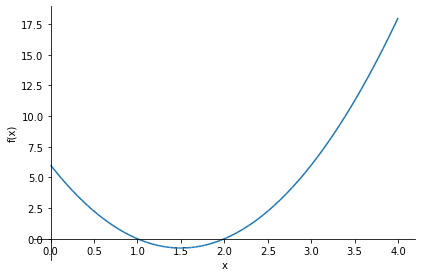

In [41]:
%matplotlib inline

pf=plot(f, (x,0, 4))

In [42]:
diff(f,x)

6*x - 9.0

In [43]:
solve(diff(f,x),x)

[1.50000000000000]

In [44]:
integrate(f,(x, 0, t))

1.0*t**3 - 4.5*t**2 + 6.0*t

In [45]:
S = integrate(f,(x, 0, t))

In [46]:
S.subs({t:1})

2.50000000000000

In [47]:
S.subs({t:2})

2.00000000000000

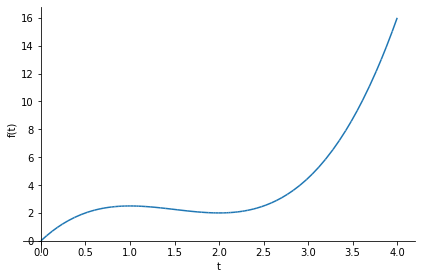

In [48]:
pS=plot(S, (t,0,4))

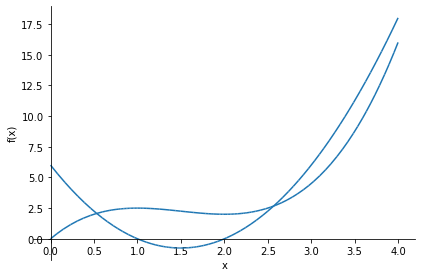

In [49]:
plot(S.subs({t:x}),f,(x,0,4))

．．．

中略

．．．

設問(3)の最終部分

以上から、すべての正の実数$p$に対して、
2点$(1- p, S(1 - p))$,
$(\fbox{ ト }, S(\fbox{ ト }))$ を
結ぶ線分の中点についての記述として、後の0~⑤のうち、
最も適当なものは$\fbox{ ネ }$である。

2点$(1- p, S(1 - p))$,
$(\fbox{ ト }, S(\fbox{ ト }))$ をP1, P2として，
p = [0,1,2,3,4,5,6]で数値的に確認をとると下記の通りとなる．
``` python
m=2
for p in [0.1, 1,2,3,4,5,6]:
    P1 = (1-p, S.subs({t:1-p}))
    P2 = (m+p, S.subs({t:m+p}))
    print((P1[0]+P2[0])/2, (P1[1]+P2[1])/2)
```

``` bash
1.5 9/4
1.5 9/4
1.5 9/4
1.5 9/4
1.5 9/4
1.5 9/4
1.5 9/4
```

In [50]:
p = 2
P1 = (1-p, S.subs({t:1-p}))
P1

(-1, -11.5000000000000)

In [51]:
P2 = (m+p, S.subs({t:m+p}))
P2

(4.0, 16.0000000000000)

In [52]:
for p in [0.1,1,2,3,4,5,6]:
    P1 = (1-p, S.subs({t:1-p}))
    P2 = (m+p, S.subs({t:m+p}))
    print((P1[0]+P2[0])/2, (P1[1]+P2[1])/2)


1.5 2.25000000000000
1.5 2.25000000000000
1.5 2.25000000000000
1.5 2.25000000000000
1.5 2.25000000000000
1.5 2.25000000000000
1.5 2.25000000000000


# 問4 共通テスト改変(20 点)

上記問３において，$m=2.5$ としたときの
$\fbox{ ア }$から$\fbox{ シ }$を埋めよ．

P1とP2の中点の座標は，p = [0,1,2,3,4,5,6]について
``` bash
1.75 2.40625000000000
1.75 2.40625000000000
1.75 2.40625000000000
1.75 2.40625000000000
1.75 2.40625000000000
1.75 2.40625000000000
1.75 2.40625000000000
```
となる．

In [53]:
from sympy import *

m, p, t, x = symbols('m p t x')
m=2.5
f=3*(x-1)*(x-m)

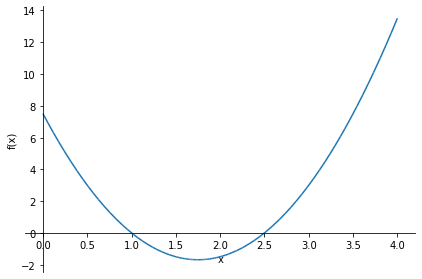

In [54]:
%matplotlib inline

pf=plot(f, (x,0, 4))

In [55]:
diff(f,x)

6*x - 10.5

In [56]:
solve(diff(f,x),x)

[1.75000000000000]

In [57]:
integrate(f,(x, 0, t))

1.0*t**3 - 5.25*t**2 + 7.5*t

In [58]:
S = integrate(f,(x, 0, t))

In [59]:
S.subs({t:1})

3.25000000000000

In [60]:
S.subs({t:2})

2.00000000000000

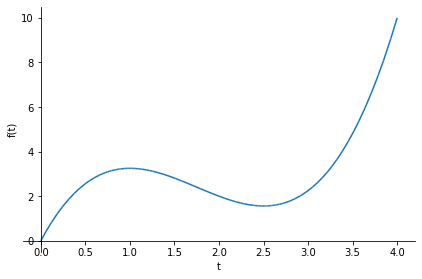

In [61]:
pS=plot(S, (t,0,4))

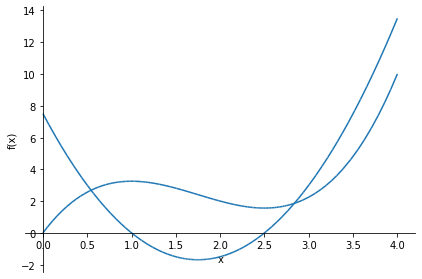

In [62]:
plot(S.subs({t:x}),f,(x,0,4))

In [63]:
p = 2
P1 = (1-p, S.subs({t:1-p}))
P1

(-1, -13.7500000000000)

In [64]:
P2 = (m+p, S.subs({t:m+p}))
P2

(4.5, 18.5625000000000)

In [65]:
for p in [0.1,1,2,3,4,5,6]:
    P1 = (1-p, S.subs({t:1-p}))
    P2 = (m+p, S.subs({t:m+p}))
    print((P1[0]+P2[0])/2, (P1[1]+P2[1])/2)


1.75 2.40625000000000
1.75 2.40625000000000
1.75 2.40625000000000
1.75 2.40625000000000
1.75 2.40625000000000
1.75 2.40625000000000
1.75 2.40625000000000
